# Florfenicol in Nile tilapia (RAS): calibrated PK + environmental fate + food-safety QRA (v3)

**What is new vs v1/v2**
- PK parameters are *calibrated* (Bayesian, adaptive Metropolis) on published time series:
  FDA NADA 141-246 Table 14 (muscle-skin FFA, 27 C) and Bowser et al. 2009 Table 1 (muscle-skin + serum, 25 C, 3 fish sizes).
- *Out-of-sample validation* on Gaikowski et al. 2010 (27 C) and on Kosoff et al. 2009 elimination times at 25 and 30 C
  (the latter as quoted in Bowser 2009 / Gaikowski 2010 / the abstract supplied by the author).
- Fish-size effect (allometric exponent b) and temperature effect (Q10) are explicit.
- One mass-conserving model: fish (gut, central, muscle) + RAS water + sludge + discharge, with a mass-balance test.
- Food safety: individual-fish variability, withdrawal by 99th-percentile rule, %ADI (ADI = 10 ug/kg bw/d, FDA FOI).
- Environment: PEC vs PNEC_res, days above PNEC, discharged load per tonne of fish, effluent-treatment mitigation.

**Modelled quantity.** All calibration data are *florfenicol amine (FFA) marker residue in muscle + skin* (acid hydrolysis converts
parent and metabolites to FFA). The model muscle state is therefore the **FFA-equivalent marker residue in muscle-skin**, and
the 1 ug/g limit is the FDA tolerance for exactly that quantity. Serum data are parent florfenicol.

**Status of parameters.** PK parameters: calibrated. Environmental parameters (`fe`, `waste`, `f_solids`, `kdeg`, `ksed`) and
`PNEC_RES`: **assumptions, not yet sourced**; see `ENV_PRIORS` and `PNEC_RES`. Environmental outputs are scenario screening
results, not validated predictions.

In [1]:
import os, sys
import numpy as np
import pandas as pd
from scipy import optimize, stats
from scipy.linalg import expm
from scipy.special import expit, logit
import matplotlib
if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

## 1. Configuration, data and scenario policy

In [2]:
SEED = 42
T_REF, W_REF, F_MUSCLE = 25.0, 0.5, 0.40     # degC, kg, kg muscle-skin per kg fish (assumed)
MRL = 1.0                                    # ug/g FFA marker, muscle + skin (FDA tolerance, NADA 141-246)
ADI_UG_KG_D, BW_CONSUMER, PORTION_G = 10.0, 60.0, 300.0   # FDA FOI ADI; consumption factor as in Gaikowski 2010
OFFICIAL_WD_D = 15.0                         # FDA label withdrawal period (days)
Z99 = 2.3263
PNEC_RES = 2.0                               # ug/L  *** UNVERIFIED placeholder: replace with a checked, cited value ***
DENSITY = 40.0                               # kg fish / m3 system water (assumed RAS density)
K_SLR = 0.5                                  # 1/day sludge removal (assumed)
EFFLUENT_TREATMENT_EFF = 0.90                # mitigation scenario (assumed efficiency)

# Environmental parameters: (median, CV) -- ALL ASSUMPTIONS (TODO: source from literature / field data)
ENV_PRIORS = {
    "fe":       (0.50, 0.30),   # fraction of eliminated drug excreted as active parent
    "waste":    (0.05, 0.50),   # fraction of offered medicated feed not ingested
    "f_solids": (0.60, 0.40),   # fraction of faecal/waste drug captured by solids filtration
    "kdeg":     (0.05, 0.60),   # 1/day degradation in water at T_REF
    "ksed":     (0.05, 0.60),   # 1/day sorption/sedimentation to sludge
}

# ---- Scenario policy ---------------------------------------------------------------------------
# 1) Temperatures are restricted to 25-30 C, the range covered by the calibration/validation data
#    (25 C: Bowser, Kosoff; 27 C: FDA, Gaikowski; 30 C: Kosoff). 22 and 32 C are run ONLY as flagged extrapolations.
# 2) Fish size 100/250/500 g (range covered by Bowser 2009).
# 3) Dose 10 mg/kg/d (label, other freshwater finfish) and 15 mg/kg/d (label maximum, warmwater finfish), 10 days.
# 4) Water exchange 5/10/20 % of system volume per day.
# 5) Mitigation: effluent treatment (assumed 90 % removal of discharged active drug).
SCENARIO_POLICY = dict(
    temps=[25.0, 27.0, 30.0], weights=[0.100, 0.250, 0.500], doses=[10.0, 15.0], qex=[0.05, 0.10, 0.20],
    extrap_temps=[22.0, 32.0], focal=dict(T=27.0, W=0.250, dose=15.0, qex=0.10), n_days=10,
)

N_MC, HORIZON_D, DT = 1000, 80, 1.0 / 8.0

def _ds(name, matrix, T, W, dose, ndays, t_d, mean, sd, n):
    return dict(name=name, matrix=matrix, T=T, W=W, dose=dose, ndays=ndays,
                t=np.array(t_d, float), mean=np.array(mean, float), sd=np.array(sd, float), n=n)

# Calibration data (time = days after the last medicated feeding). Source tables are in the papers supplied.
CALIB = [
    _ds("FDA Table 14 (447 g, 27C, 19.6 mg/kg)", "muscle", 27.0, 0.447, 19.6, 10,
        np.array([1, 12, 24, 36, 48, 72, 96, 120, 240]) / 24,
        [13.77, 13.45, 7.67, 5.74, 4.97, 2.84, 2.16, 1.38, 0.39],
        [5.21, 4.39, 3.27, 2.58, 1.33, 1.66, 0.78, 0.53, 0.16], 20),
    # Bowser 2009, 15 mg/kg/d x 10 d, 25 C. Late points (>=8 d for 100/250 g; >=28 d) sit on a ~0.1-0.4 ug/g floor
    # (LOQ-substituted) and are excluded from calibration.
    _ds("Bowser 100 g muscle-skin", "muscle", 25.0, 0.097, 15.0, 10, [0.04, 1, 2, 4],
        [10.94, 5.91, 3.48, 1.81], [2.60, 1.92, 2.07, 1.10], 15),
    _ds("Bowser 250 g muscle-skin", "muscle", 25.0, 0.257, 15.0, 10, [0.04, 1, 2, 4],
        [8.70, 7.27, 3.52, 1.46], [2.83, 2.40, 1.09, 0.99], 15),
    _ds("Bowser 500 g muscle-skin", "muscle", 25.0, 0.510, 15.0, 10, [0.04, 1, 2, 4, 8, 14],
        [16.28, 12.93, 8.05, 4.75, 1.38, 0.50], [5.07, 5.40, 2.87, 2.17, 0.89, 0.39], 15),
    _ds("Bowser 100 g serum", "serum", 25.0, 0.097, 15.0, 10, [0.04, 1, 2], [7.26, 1.06, 0.16], [2.81, 0.65, 0.07], 15),
    _ds("Bowser 250 g serum", "serum", 25.0, 0.257, 15.0, 10, [0.04, 1, 2], [7.02, 2.18, 0.36], [2.62, 1.54, 0.20], 15),
    _ds("Bowser 500 g serum", "serum", 25.0, 0.510, 15.0, 10, [0.04, 1, 2], [11.51, 4.87, 1.68], [4.94, 2.04, 1.10], 15),
]
# Validation data (NOT used in calibration)
GAIK = _ds("Gaikowski 2010 (27C, ~13 mg/kg x 12 d)", "muscle", 27.0, 0.50, 13.1, 12, [1, 2, 4, 7],
           [0.92, 0.81, 0.28, 0.14], [0.57, 0.52, 0.14, 0.04], 20)    # mean of Nile and hybrid tilapia, Table 1
KOSOFF = {25.0: 6.1, 30.0: 4.1}      # d to reach 1 ug/g, 10 mg/kg x 10 d, ~474 g (as quoted; Kosoff paper itself not supplied)
GAIK_T_HALF, GAIK_TOL_TIME = 2.32, 6.14   # d; regression half-life and tolerance-limit time (Gaikowski 2010)

# Individual-fish variability from the reported SD/mean of the calibration data (includes assay error)
_cv = np.concatenate([d["sd"] / d["mean"] for d in CALIB if d["matrix"] == "muscle"])
SIGMA_IND = float(np.sqrt(np.log(1 + np.median(_cv) ** 2)))

PK_NAMES = ["ka", "kel", "kmc", "Kp", "Vc", "F", "b", "Q10", "sigma"]
# priors on the transformed scale: (mean, sd) for [ln ka, ln kel, ln kmc, ln Kp, ln Vc, logit F, b, ln Q10, ln sigma]
PRIOR_MU = np.array([np.log(3.0), 0.0, np.log(0.5), np.log(1.5), 0.0, logit(0.8), 0.25, np.log(2.1), np.log(0.4)])
PRIOR_SD = np.array([0.7, 0.8, 0.8, 1.0, 0.6, 0.5, 0.10, 0.15, 0.5])

## 2. PK model (closed form) and Bayesian calibration
States per kg fish: gut `Ag`, central `Ac`, muscle `Am`. Rate constants scale with temperature (Q10) and with body mass (exponent b):
`kel, kmc ~ Q10^((T-25)/10) * (W/0.5)^-b`; `kcm = kmc * Kp * f_muscle / Vc` (Kp = muscle:central concentration ratio at equilibrium).

In [3]:
def to_theta(phi):
    ka, kel, kmc, Kp, Vc = np.exp(phi[:5]); F = expit(phi[5]); b = phi[6]; Q10 = np.exp(phi[7]); sg = np.exp(phi[8])
    return dict(ka=ka, kel=kel, kmc=kmc, Kp=Kp, Vc=Vc, F=F, b=b, Q10=Q10, sigma=sg)

def pk_closed(th, T, W, dose, ndays, t_after):
    """Muscle (ug/g) and central (ug/mL) concentration at times (days) after the last dose; daily pulses into the gut."""
    sT = th["Q10"] ** ((T - T_REF) / 10.0); sW = (W / W_REF) ** (-th["b"])
    ka, kel, kmc = th["ka"] * sT, th["kel"] * sT * sW, th["kmc"] * sT * sW
    kcm = kmc * th["Kp"] * F_MUSCLE / th["Vc"]
    A = np.array([[-ka, 0, 0], [th["F"] * ka, -(kel + kcm), kmc], [0, kcm, -kmc]])
    lam, V = np.linalg.eig(A); lam, V = lam.real, V.real
    c = np.linalg.solve(V, np.array([1.0, 0, 0]))
    t = (ndays - 1) + np.asarray(t_after, float)
    E = np.exp(lam[None, None, :] * (t[:, None, None] - np.arange(ndays)[None, :, None])).sum(1)
    x = (E * c[None, :]) @ V.T * dose
    return x[:, 1] / th["Vc"], x[:, 2] / F_MUSCLE

def log_post(phi, data=CALIB):
    if not (0.0 <= phi[6] <= 1.0): return -np.inf
    lp = -0.5 * np.sum(((phi - PRIOR_MU) / PRIOR_SD) ** 2)
    th = to_theta(phi)
    try:
        for d in data:
            cc, cm = pk_closed(th, d["T"], d["W"], d["dose"], d["ndays"], d["t"])
            pred = cm if d["matrix"] == "muscle" else cc
            if np.any(pred <= 0) or not np.all(np.isfinite(pred)): return -np.inf
            r = np.log(d["mean"]) - np.log(pred)
            lp += -len(r) * np.log(th["sigma"]) - 0.5 * np.sum(r ** 2) / th["sigma"] ** 2
    except np.linalg.LinAlgError:
        return -np.inf
    return lp

def find_map(rng, n_starts=6):
    best = None
    for i in range(n_starts):
        x0 = PRIOR_MU + (rng.normal(0, 0.3, len(PRIOR_MU)) * PRIOR_SD if i else 0)
        r = optimize.minimize(lambda p: -log_post(p) if np.isfinite(log_post(p)) else 1e12, x0,
                              method="Nelder-Mead", options=dict(maxiter=6000, xatol=1e-4, fatol=1e-6))
        if best is None or r.fun < best.fun: best = r
    return best.x

def adaptive_metropolis(x0, n_iter, rng, adapt_from=1500):
    d = len(x0); x = x0.copy(); lp = log_post(x); chain = np.empty((n_iter, d)); acc = 0
    cov = np.diag((PRIOR_SD * 0.05) ** 2); sd = 2.38 ** 2 / d
    for i in range(n_iter):
        if i >= adapt_from and i % 250 == 0:
            cov = np.cov(chain[:i].T) + 1e-8 * np.eye(d)
        prop = rng.multivariate_normal(x, sd * cov)
        lp_p = log_post(prop)
        if np.log(rng.uniform()) < lp_p - lp: x, lp = prop, lp_p; acc += 1
        chain[i] = x
    return chain, acc / n_iter

def rhat(chains):
    m, n = chains.shape[0], chains.shape[1]
    W = chains.var(axis=1, ddof=1).mean(0); B = n * chains.mean(1).var(axis=0, ddof=1)
    return np.sqrt(((n - 1) / n * W + B / n) / W)

def calibrate(rng, n_chains=4, n_iter=12000, burn=4000, thin=8):
    x_map = find_map(rng)
    chains, accs = [], []
    for k in range(n_chains):
        c, a = adaptive_metropolis(x_map + rng.normal(0, 0.02, len(x_map)) * PRIOR_SD, n_iter, rng)
        chains.append(c[burn:]); accs.append(a)
    chains = np.array(chains)
    post = chains[:, ::thin, :].reshape(-1, chains.shape[2])
    return x_map, post, rhat(chains[:, ::thin, :]), float(np.mean(accs))

def predict_post(post, d, n=300, rng=None, noise=False):
    rng = rng or np.random.default_rng(0); idx = rng.choice(len(post), n, replace=False); out = []
    for i in idx:
        th = to_theta(post[i]); cc, cm = pk_closed(th, d["T"], d["W"], d["dose"], d["ndays"], d["t"])
        y = cm if d["matrix"] == "muscle" else cc
        out.append(y * np.exp(rng.normal(0, th["sigma"], len(y))) if noise else y)
    return np.array(out)

def fit_metrics(post, data, rng):
    rows = []
    for d in data:
        p = predict_post(post, d, rng=rng, noise=False); pn = predict_post(post, d, rng=rng, noise=True)
        med = np.median(p, 0); lo, hi = np.percentile(pn, [5, 95], 0)
        r = np.log(d["mean"]) - np.log(med)
        rows.append(dict(dataset=d["name"], n_points=len(r), RMSE_log=float(np.sqrt(np.mean(r ** 2))),
                         geo_mean_fold_error=float(np.exp(np.mean(np.abs(r)))),
                         coverage_90_pred=float(np.mean((d["mean"] >= lo) & (d["mean"] <= hi)))))
    return pd.DataFrame(rows)

## 3. Validation (out-of-sample)

In [4]:
def time_to_cross(th, T, W, dose, ndays, thr=MRL, tmax=80, step=0.02):
    t = np.arange(0, tmax, step); _, cm = pk_closed(th, T, W, dose, ndays, t)
    above = cm > thr
    return float(t[np.where(above)[0][-1] + 1]) if above.any() else 0.0

def terminal_half_life(th, T, W, dose, ndays, t0=2.0, t1=8.0):
    t = np.linspace(t0, t1, 30); _, cm = pk_closed(th, T, W, dose, ndays, t)
    return float(-np.log(2) / np.polyfit(t, np.log(cm), 1)[0])

def validate(post, rng, n=400):
    idx = rng.choice(len(post), n, replace=False); th_s = [to_theta(post[i]) for i in idx]; rows = []
    cm_g = np.array([pk_closed(th, GAIK["T"], GAIK["W"], GAIK["dose"], GAIK["ndays"], GAIK["t"])[1] for th in th_s])
    fold = np.exp(np.log(GAIK["mean"]) - np.log(np.median(cm_g, 0)))
    rows.append(dict(test="Gaikowski 2010 mean FFA, day 1/2/4/7: observed/predicted (fold)",
                     result=" / ".join(f"{f:.2f}" for f in fold),
                     comment="<1 means the model over-predicts the concentration level"))
    rows.append(dict(test="Gaikowski 2010 shape: log-slope ratio (obs. half-life 2.32 d)",
                     result=f"model terminal t1/2 (2-8 d) = {np.median([terminal_half_life(th, 27, 0.5, 13.1, 12) for th in th_s]):.2f} d",
                     comment="compares depletion rate, independent of the concentration-level offset"))
    c1 = np.array([pk_closed(th, 25.0, 0.474, 10.0, 10, np.array([1.0]))[1][0] for th in th_s])
    rows.append(dict(test="Kosoff 2009 day-1 muscle-skin FFA at 25 C, 10 mg/kg (obs. 7.10 ug/g, as quoted in Gaikowski 2010)",
                     result=f"{np.median(c1):.1f} ug/g (90% CrI {np.percentile(c1, 5):.1f}-{np.percentile(c1, 95):.1f})",
                     comment="concentration-level test against a third study"))
    for T, tobs in KOSOFF.items():
        tm = np.array([time_to_cross(th, T, 0.474, 10.0, 10) for th in th_s])
        rows.append(dict(test=f"Kosoff 2009 time to 1 ug/g at {T:.0f} C, 10 mg/kg (obs. {tobs} d)",
                         result=f"{np.median(tm):.1f} d (90% CrI {np.percentile(tm, 5):.1f}-{np.percentile(tm, 95):.1f})",
                         comment="out-of-sample temperature test" if T == 30.0 else "within calibrated temperature"))
    return pd.DataFrame(rows), cm_g

## 4. Integrated fish-water-sludge system (Monte Carlo, vectorised)
State vector (fish states per kg fish; water/sludge/cumulative states in mg per m3 of system water = ug/L):
`[Ag, Ac, Am, Cw, Ssl, E_eff, E_slu, E_deg, E_met, E_cap]`. Total mass is conserved (checked in `run_checks`).

In [5]:
def sample_env(n, rng):
    out = {}
    for k, (med, cv) in ENV_PRIORS.items():
        s = np.sqrt(np.log(1 + cv ** 2)); out[k] = med * np.exp(rng.normal(0, s, n))
    for k in ("fe", "waste", "f_solids"): out[k] = np.clip(out[k], 1e-3, 0.98)
    return out

def draw_params(post, n, rng):
    th = [to_theta(post[i]) for i in rng.choice(len(post), n, replace=True)]
    p = {k: np.array([t[k] for t in th]) for k in PK_NAMES}; p.update(sample_env(n, rng)); return p

def build_A(p, T, W, qex):
    n = len(p["ka"]); sT = p["Q10"] ** ((T - T_REF) / 10.0); sW = (W / W_REF) ** (-p["b"]); d = DENSITY
    ka, kel, kmc, kdeg = p["ka"] * sT, p["kel"] * sT * sW, p["kmc"] * sT * sW, p["kdeg"] * sT
    kcm = kmc * p["Kp"] * F_MUSCLE / p["Vc"]; F, fe, fs, ksed = p["F"], p["fe"], p["f_solids"], p["ksed"]
    A = np.zeros((n, 10, 10))
    A[:, 0, 0] = -ka
    A[:, 1, 0] = F * ka;  A[:, 1, 1] = -(kel + kcm);  A[:, 1, 2] = kmc
    A[:, 2, 1] = kcm;     A[:, 2, 2] = -kmc
    A[:, 3, 0] = d * (1 - F) * (1 - fs) * ka;  A[:, 3, 1] = d * fe * kel;  A[:, 3, 3] = -(qex + kdeg + ksed)
    A[:, 4, 3] = ksed;    A[:, 4, 4] = -K_SLR
    A[:, 5, 3] = qex;     A[:, 6, 4] = K_SLR;  A[:, 7, 3] = kdeg
    A[:, 8, 1] = d * (1 - fe) * kel
    A[:, 9, 0] = d * (1 - F) * fs * ka
    return A

def simulate(p, T, W, dose, qex, ndays=10, horizon=HORIZON_D, dt=DT, keep_states=False):
    n = len(p["ka"]); phi = expm(build_A(p, T, W, qex) * dt)
    spd = int(round(1 / dt)); steps = int(horizon / dt)
    x = np.zeros((n, 10)); cm = np.empty((steps, n)); cw = np.empty((steps, n)); allx = [] if keep_states else None
    for s in range(steps):
        if s % spd == 0 and s // spd < ndays:
            x[:, 0] += (1 - p["waste"]) * dose
            x[:, 3] += DENSITY * (1 - p["f_solids"]) * p["waste"] * dose
            x[:, 9] += DENSITY * p["f_solids"] * p["waste"] * dose
        x = np.einsum("nij,nj->ni", phi, x)
        cm[s] = x[:, 2] / F_MUSCLE; cw[s] = x[:, 3]
        if keep_states: allx.append(x.copy())
    t = (np.arange(steps) + 1) * dt
    return dict(t=t, cm=cm, cw=cw, x_end=x.copy(), states=np.array(allx) if keep_states else None, ndays=ndays, dt=dt)

def time_after_last_dose_below(series, thr, ndays, dt):
    """Days after the LAST medicated feeding (last pulse at day ndays-1, as in the calibration data) until series <= thr for good."""
    n0 = int(round((ndays - 1) / dt)); above = series > thr; above[:n0] = False
    last = series.shape[0] - 1 - np.argmax(above[::-1], axis=0)
    t = np.where(above.any(0), (last + 1) * dt - (ndays - 1), 0.0)
    return t, above[-1]

def idx_after(ndays, dt, t_after): return int(round((ndays - 1) / dt)) + int(round(t_after / dt)) - 1

## 5. Risk metrics (food safety, environment, mitigation)

In [6]:
def scenario_metrics(sim, T, W, dose, qex):
    nd, dt = sim["ndays"], sim["dt"]; cm, cw = sim["cm"], sim["cw"]
    c99_thr = MRL * np.exp(-Z99 * SIGMA_IND)                          # median conc. whose 99th-percentile individual = MRL
    t_med, _ = time_after_last_dose_below(cm, MRL, nd, dt)           # median-fish crossing
    t99, cens = time_after_last_dose_below(cm, c99_thr, nd, dt)      # 99th-percentile-individual rule
    i15 = idx_after(nd, dt, OFFICIAL_WD_D); cm15 = cm[i15]
    p_ind = 1 - stats.norm.cdf((np.log(MRL) - np.log(cm15)) / SIGMA_IND)   # P(individual fillet > MRL at 15 d)
    pct_adi_p99 = cm15 * np.exp(Z99 * SIGMA_IND) * PORTION_G / (ADI_UG_KG_D * BW_CONSUMER) * 100
    rq = cw.max(0) / PNEC_RES; t_pnec, _ = time_after_last_dose_below(cw, PNEC_RES, nd, dt)
    days_above = (cw > PNEC_RES).sum(0) * dt
    load_eff = sim["x_end"][:, 5] / DENSITY; load_slu = sim["x_end"][:, 6] / DENSITY    # g per tonne fish
    q = lambda v, a: float(np.percentile(v, a))
    row = dict(T_C=T, W_g=W * 1000, dose_mg_kg_d=dose, water_exchange_per_d=qex,
               t_MRL_median_d=q(t_med, 50), t99_median_d=q(t99, 50), t99_p95_d=q(t99, 95),
               t99_p95_degree_days=q(t99, 95) * T, official_wd_degree_days=OFFICIAL_WD_D * T,
               P_draws_t99_gt_official=float(np.mean(t99 > OFFICIAL_WD_D)),
               P_individual_gt_MRL_at_15d=float(np.mean(p_ind)),
               pct_ADI_p99_at_15d_median=q(pct_adi_p99, 50), pct_ADI_p99_at_15d_p95=q(pct_adi_p99, 95),
               PEC_max_median_ugL=q(cw.max(0), 50), PEC_max_p95_ugL=q(cw.max(0), 95),
               RQ_max_median=q(rq, 50), RQ_max_p95=q(rq, 95), days_above_PNEC_median=q(days_above, 50),
               t_PNEC_after_last_dose_median_d=q(t_pnec, 50), t_PNEC_after_last_dose_p95_d=q(t_pnec, 95),
               discharge_g_per_t_fish_median=q(load_eff, 50),
               discharge_treated_g_per_t_fish_median=q(load_eff * (1 - EFFLUENT_TREATMENT_EFF), 50),
               sludge_g_per_t_fish_median=q(load_slu, 50), frac_censored=float(np.mean(cens)))
    return row, dict(t99=t99, rq=rq, load=load_eff)

def prcc(X, y):
    R = np.column_stack([stats.rankdata(X[:, j]) for j in range(X.shape[1])]); ry = stats.rankdata(y); out = []
    for j in range(R.shape[1]):
        o = np.delete(R, j, 1); o = np.column_stack([np.ones(len(ry)), o])
        rx = R[:, j] - o @ np.linalg.lstsq(o, R[:, j], rcond=None)[0]
        rr = ry - o @ np.linalg.lstsq(o, ry, rcond=None)[0]
        out.append(np.corrcoef(rx, rr)[0, 1] if rx.std() > 0 and rr.std() > 0 else 0.0)
    return np.array(out)

## 6. Self-checks (closed form vs time stepping; mass conservation)

In [7]:
def run_checks(post, rng):
    p = draw_params(post, 5, rng); out = {}
    for k in ("waste",): p[k] = np.full(5, 0.0)
    sim = simulate(p, 27.0, 0.25, 15.0, 0.10, keep_states=True)
    th0 = {k: p[k][0] for k in PK_NAMES}; t_after = np.array([0.5, 2.0, 5.0, 10.0])
    cm_closed = pk_closed(th0, 27.0, 0.25, 15.0, 10, t_after)[1]
    cm_step = np.array([sim["cm"][idx_after(10, DT, t), 0] for t in t_after])
    out["closed_vs_stepping_max_rel_err"] = float(np.max(np.abs(cm_closed / cm_step - 1)))
    p2 = draw_params(post, 5, rng); sim2 = simulate(p2, 27.0, 0.25, 15.0, 0.10, keep_states=True)
    S = sim2["states"]; tt = sim2["t"]; npulse = np.minimum(np.floor(tt - 1e-9) + 1, 10)
    total = DENSITY * S[:, :, 0:3].sum(2) + S[:, :, 3:].sum(2)
    expected = DENSITY * 15.0 * npulse[:, None]
    out["mass_balance_max_rel_err"] = float(np.max(np.abs(total - expected)) / (DENSITY * 15.0 * 10))
    return out

## 7. Figures (npj style: Arial/Helvetica, colour-blind-safe palette, 300 dpi)

In [8]:
OI = dict(blue="#0072B2", orange="#E69F00", green="#009E73", verm="#D55E00", purple="#CC79A7", sky="#56B4E9", grey="#555555")

def style():
    plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
                         "font.size": 8, "axes.linewidth": 0.8, "figure.dpi": 110})

def _lab(axs):
    for a, l in zip(np.ravel(axs), "abcdefgh"):
        a.text(-0.27, 1.05, l, transform=a.transAxes, fontweight="bold", fontsize=9); a.spines[["top", "right"]].set_visible(False)

def fig_calibration(post, rng, fname):
    style(); fig, ax = plt.subplots(1, 3, figsize=(7.2, 2.6)); tg = np.linspace(0.02, 14, 120)
    def band(a, d, color, label):
        dd = dict(d); dd["t"] = tg; p = predict_post(post, dd, n=300, rng=rng)
        lo, md, hi = np.percentile(p, [5, 50, 95], 0); a.fill_between(tg, lo, hi, color=color, alpha=0.2, lw=0); a.plot(tg, md, color=color, lw=1)
        a.errorbar(d["t"], d["mean"], d["sd"], fmt="o", ms=3, color=color, capsize=1.5, lw=0.7, label=label)
    band(ax[0], CALIB[0], OI["blue"], "FDA, 447 g, 27 °C")
    for d, c, l in zip(CALIB[1:4], [OI["orange"], OI["green"], OI["purple"]], ["100 g", "250 g", "500 g"]): band(ax[1], d, c, l)
    for d, c, l in zip(CALIB[4:], [OI["orange"], OI["green"], OI["purple"]], ["100 g", "250 g", "500 g"]): band(ax[2], d, c, l)
    for a, yl in zip(ax, ["Muscle–skin FFA (µg g$^{-1}$)", "Muscle–skin FFA (µg g$^{-1}$)", "Serum florfenicol (µg mL$^{-1}$)"]):
        a.set_yscale("log"); a.set_xlabel("Days after last dose"); a.set_ylabel(yl); a.legend(frameon=False, fontsize=6.5)
    ax[0].set_xlim(0, 11); ax[0].set_ylim(0.1, 30); ax[1].set_xlim(0, 15); ax[1].set_ylim(0.1, 40); ax[2].set_xlim(0, 3.5); ax[2].set_ylim(0.05, 30)
    ax[0].axhline(MRL, color=OI["grey"], ls="--", lw=0.7); ax[1].axhline(MRL, color=OI["grey"], ls="--", lw=0.7)
    _lab(ax); fig.tight_layout(); fig.savefig(fname, dpi=300); plt.close(fig)

def fig_validation(cm_g, vtab, post, rng, fname):
    style(); fig, ax = plt.subplots(1, 2, figsize=(5.2, 2.5)); lo, md, hi = np.percentile(cm_g, [5, 50, 95], 0)
    ax[0].fill_between(GAIK["t"], lo, hi, color=OI["blue"], alpha=0.2, lw=0); ax[0].plot(GAIK["t"], md, color=OI["blue"], marker="s", ms=3, lw=1, label="Model (calibrated on FDA + Bowser)")
    ax[0].errorbar(GAIK["t"], GAIK["mean"], GAIK["sd"], fmt="o", color=OI["verm"], ms=3, capsize=1.5, lw=0.7, label="Gaikowski 2010 (not used for fitting)")
    ax[0].set_yscale("log"); ax[0].set_xlabel("Days after last dose"); ax[0].set_ylabel("Muscle–skin FFA (µg g$^{-1}$)"); ax[0].set_ylim(0.05, 60); ax[0].legend(frameon=False, fontsize=6, loc="upper right")
    idx = rng.choice(len(post), 400, replace=False)
    for k, (T, tobs) in enumerate(KOSOFF.items()):
        tm = np.array([time_to_cross(to_theta(post[i]), T, 0.474, 10.0, 10) for i in idx]); q = np.percentile(tm, [5, 50, 95])
        ax[1].errorbar(k, q[1], [[q[1] - q[0]], [q[2] - q[1]]], fmt="o", color=OI["blue"], capsize=2, ms=4, label="Model (median, 90% CrI)" if k == 0 else None)
        ax[1].plot(k, tobs, "D", color=OI["verm"], ms=4, label="Kosoff 2009 (as quoted)" if k == 0 else None)
    ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(["25 °C", "30 °C"]); ax[1].set_ylabel("Days to reach 1 µg g$^{-1}$"); ax[1].legend(frameon=False, fontsize=6)
    _lab(ax); fig.tight_layout(); fig.savefig(fname, dpi=300); plt.close(fig)

def fig_food(tab, fname):
    style(); fig, ax = plt.subplots(1, 3, figsize=(7.2, 2.5)); sub = tab[(tab.dose_mg_kg_d == 15) & (tab.water_exchange_per_d == 0.10) & (~tab.get("extrapolated", False))]
    cols = {100: OI["orange"], 250: OI["green"], 500: OI["purple"]}
    for w, c in cols.items():
        s = sub[sub.W_g == w].sort_values("T_C")
        ax[0].plot(s.T_C, s.t99_median_d, "-o", ms=3, color=c, label=f"{w} g"); ax[0].fill_between(s.T_C, s.t99_median_d, s.t99_p95_d, color=c, alpha=0.15, lw=0)
        ax[1].plot(s.T_C, s.t99_p95_degree_days, "-o", ms=3, color=c); ax[2].plot(s.T_C, s.pct_ADI_p99_at_15d_median, "-o", ms=3, color=c)
    ax[0].axhline(OFFICIAL_WD_D, color=OI["grey"], ls="--", lw=0.7); ax[0].text(25.1, OFFICIAL_WD_D + 0.3, "Label: 15 d", fontsize=6.5, color=OI["grey"])
    ax[1].plot(sorted(sub.T_C.unique()), [OFFICIAL_WD_D * t for t in sorted(sub.T_C.unique())], "--", color=OI["grey"], lw=0.7); ax[1].text(25.1, 15 * 25 + 12, "Label: 15 d", fontsize=6.5, color=OI["grey"])
    ax[2].axhline(50, color=OI["grey"], ls="--", lw=0.7); ax[2].text(25.1, 52, "50 % ADI (at 1 µg g$^{-1}$)", fontsize=6.5, color=OI["grey"])
    ax[0].set_ylabel("Withdrawal, 99th-percentile rule (d)\nmedian (line) to P95 (band)"); ax[1].set_ylabel("P95 withdrawal (degree-days)"); ax[2].set_ylabel("% ADI, 99th-pct fillet at 15 d")
    for a in ax: a.set_xlabel("Water temperature (°C)")
    ax[0].legend(frameon=False, fontsize=6.5); _lab(ax); fig.tight_layout(); fig.savefig(fname, dpi=300); plt.close(fig)

def fig_env(p, tab, fname):
    style(); fig, ax = plt.subplots(1, 3, figsize=(7.2, 2.5)); f = SCENARIO_POLICY["focal"]
    for q, c in zip(SCENARIO_POLICY["qex"], [OI["orange"], OI["blue"], OI["green"]]):
        sim = simulate(p, f["T"], f["W"], f["dose"], q); lo, md, hi = np.percentile(sim["cw"], [5, 50, 95], 1)
        ax[0].fill_between(sim["t"], lo, hi, color=c, alpha=0.15, lw=0); ax[0].plot(sim["t"], md, color=c, lw=1, label=f"{int(q*100)} % d$^{{-1}}$")
    ax[0].axhline(PNEC_RES, color=OI["grey"], ls="--", lw=0.7); ax[0].text(59, PNEC_RES * 1.3, "PNEC$_{res}$ (unverified)", fontsize=6.5, ha="right", color=OI["grey"]); ax[0].text(0.03, 0.04, "Absolute levels depend on\nunsourced assumptions", transform=ax[0].transAxes, fontsize=6, color=OI["grey"])
    ax[0].set_yscale("log"); ax[0].set_ylim(0.01, None); ax[0].set_xlim(0, 60); ax[0].set_xlabel("Days"); ax[0].set_ylabel("Water concentration (µg L$^{-1}$)"); ax[0].legend(frameon=False, fontsize=6.5, title="Water exchange", title_fontsize=6.5, loc="upper right")
    sub = tab[(tab.T_C == f["T"]) & (tab.W_g == f["W"] * 1000) & (tab.dose_mg_kg_d == f["dose"])].sort_values("water_exchange_per_d")
    x = np.arange(len(sub)); ax[1].bar(x - 0.2, sub.discharge_g_per_t_fish_median, 0.4, color=OI["blue"], label="Untreated effluent")
    ax[1].bar(x + 0.2, sub.discharge_treated_g_per_t_fish_median, 0.4, color=OI["orange"], label=f"Treated ({int(EFFLUENT_TREATMENT_EFF*100)} % removal)")
    ax[1].set_xticks(x); ax[1].set_xticklabels([f"{int(q*100)} %" for q in sub.water_exchange_per_d]); ax[1].set_xlabel("Water exchange (d$^{-1}$)"); ax[1].set_ylabel("Active drug discharged (g t$^{-1}$ fish)"); ax[1].set_ylim(0, sub.discharge_g_per_t_fish_median.max() * 1.45); ax[1].legend(frameon=False, fontsize=6.5, loc="upper left")
    ax[2].bar(x, sub.RQ_max_median, color=OI["verm"]); ax[2].errorbar(x, sub.RQ_max_median, [np.zeros(len(x)), sub.RQ_max_p95 - sub.RQ_max_median], fmt="none", color="k", capsize=2, lw=0.7)
    ax[2].set_xticks(x); ax[2].set_xticklabels([f"{int(q*100)} %" for q in sub.water_exchange_per_d]); ax[2].set_xlabel("Water exchange (d$^{-1}$)"); ax[2].set_ylabel("Max risk quotient (median, P95)")
    _lab(ax); fig.tight_layout(); fig.savefig(fname, dpi=300); plt.close(fig)

def fig_prcc(df, fname):
    style(); fig, ax = plt.subplots(figsize=(4.6, 3.0)); idx = np.arange(len(df)); w = 0.27
    for k, (c, col) in enumerate(zip(df.columns, [OI["blue"], OI["verm"], OI["green"]])): ax.barh(idx + (k - 1) * w, df[c], w, color=col, label=c)
    ax.set_yticks(idx); ax.set_yticklabels(df.index); ax.axvline(0, color="k", lw=0.6); ax.set_xlabel("PRCC"); ax.legend(frameon=False, fontsize=6.5)
    ax.spines[["top", "right"]].set_visible(False); fig.tight_layout(); fig.savefig(fname, dpi=300); plt.close(fig)

## 8. Run everything

In [9]:
def run_all(outdir=".", n_iter=12000):
    os.makedirs(outdir, exist_ok=True); rng = np.random.default_rng(SEED)
    print("=" * 90 + "\nPK parameters: calibrated.  Environmental parameters and PNEC_RES: ASSUMPTIONS (unsourced).\n" + "=" * 90)
    print(f"Individual-fish sigma (ln scale) from reported CVs: {SIGMA_IND:.3f}")
    x_map, post, rh, acc = calibrate(rng, n_iter=n_iter)
    th = pd.DataFrame([to_theta(r) for r in post]); summ = th.describe(percentiles=[.025, .5, .975]).T[["2.5%", "50%", "97.5%"]]
    summ["R_hat"] = rh; summ.to_csv(f"{outdir}/calibration_posterior.csv"); print(f"\nPosterior (median, 95% CrI), R-hat; acceptance={acc:.2f}"); print(summ.round(3).to_string())
    fm = fit_metrics(post, CALIB, rng); fm.to_csv(f"{outdir}/calibration_fit_metrics.csv", index=False); print("\nCalibration fit"); print(fm.round(3).to_string(index=False))
    vtab, cm_g = validate(post, rng); vtab.to_csv(f"{outdir}/validation.csv", index=False); print("\nValidation"); print(vtab.to_string(index=False))
    chk = run_checks(post, rng); print("\nChecks:", chk)

    p = draw_params(post, N_MC, rng); rows, store, S = [], {}, SCENARIO_POLICY
    grid = [(T, W, d, q, False) for T in S["temps"] for W in S["weights"] for d in S["doses"] for q in S["qex"]]
    grid += [(T, 0.250, 15.0, 0.10, True) for T in S["extrap_temps"]]
    for T, W, d, q, ex in grid:
        sim = simulate(p, T, W, d, q, ndays=S["n_days"]); row, aux = scenario_metrics(sim, T, W, d, q); row["extrapolated"] = ex; rows.append(row); store[(T, W, d, q)] = aux
    tab = pd.DataFrame(rows); tab.to_csv(f"{outdir}/scenario_summary.csv", index=False)
    cols = ["T_C", "W_g", "dose_mg_kg_d", "water_exchange_per_d", "t99_median_d", "t99_p95_d", "P_draws_t99_gt_official", "pct_ADI_p99_at_15d_median", "RQ_max_median", "discharge_g_per_t_fish_median"]
    print("\nScenario summary (excerpt)"); print(tab[cols].round(2).to_string(index=False))

    f = S["focal"]; aux = store[(f["T"], f["W"], f["dose"], f["qex"])]
    X = np.column_stack([p[k] for k in PK_NAMES[:-1] + list(ENV_PRIORS)]); names = PK_NAMES[:-1] + list(ENV_PRIORS)
    df = pd.DataFrame({"Withdrawal (t99)": prcc(X, aux["t99"]), "Max risk quotient": prcc(X, aux["rq"]), "Discharged load": prcc(X, aux["load"])}, index=names)
    df.to_csv(f"{outdir}/sensitivity_prcc.csv"); print("\nPRCC (focal scenario)"); print(df.round(2).to_string())

    fig_calibration(post, rng, f"{outdir}/fig1_calibration.png"); fig_validation(cm_g, vtab, post, rng, f"{outdir}/fig2_validation.png")
    fig_food(tab, f"{outdir}/fig3_withdrawal_adi.png"); fig_env(p, tab, f"{outdir}/fig4_environment.png"); fig_prcc(df, f"{outdir}/fig5_prcc.png")
    return dict(post=post, tab=tab, summ=summ, fm=fm, vtab=vtab, chk=chk, prcc=df)

## 9. Execute the full analysis (about 1-2 minutes)

PK parameters: calibrated.  Environmental parameters and PNEC_RES: ASSUMPTIONS (unsourced).
Individual-fish sigma (ln scale) from reported CVs: 0.371

Posterior (median, 95% CrI), R-hat; acceptance=0.32
        2.5%    50%   97.5%  R_hat
ka     3.296  7.557  20.623  1.001
kel    1.365  2.066   3.526  1.003
kmc    0.243  0.306   0.379  1.003
Kp     0.761  1.139   1.797  1.000
Vc     0.337  0.703   1.432  1.002
F      0.668  0.825   0.924  1.001
b      0.208  0.327   0.444  1.002
Q10    1.778  2.366   3.134  1.005
sigma  0.337  0.434   0.581  1.000

Calibration fit
                              dataset  n_points  RMSE_log  geo_mean_fold_error  coverage_90_pred
FDA Table 14 (447 g, 27C, 19.6 mg/kg)         9     0.401                1.455              1.00
             Bowser 100 g muscle-skin         4     0.418                1.372              0.75
             Bowser 250 g muscle-skin         4     0.382                1.369              1.00
             Bowser 500 g muscle-skin     

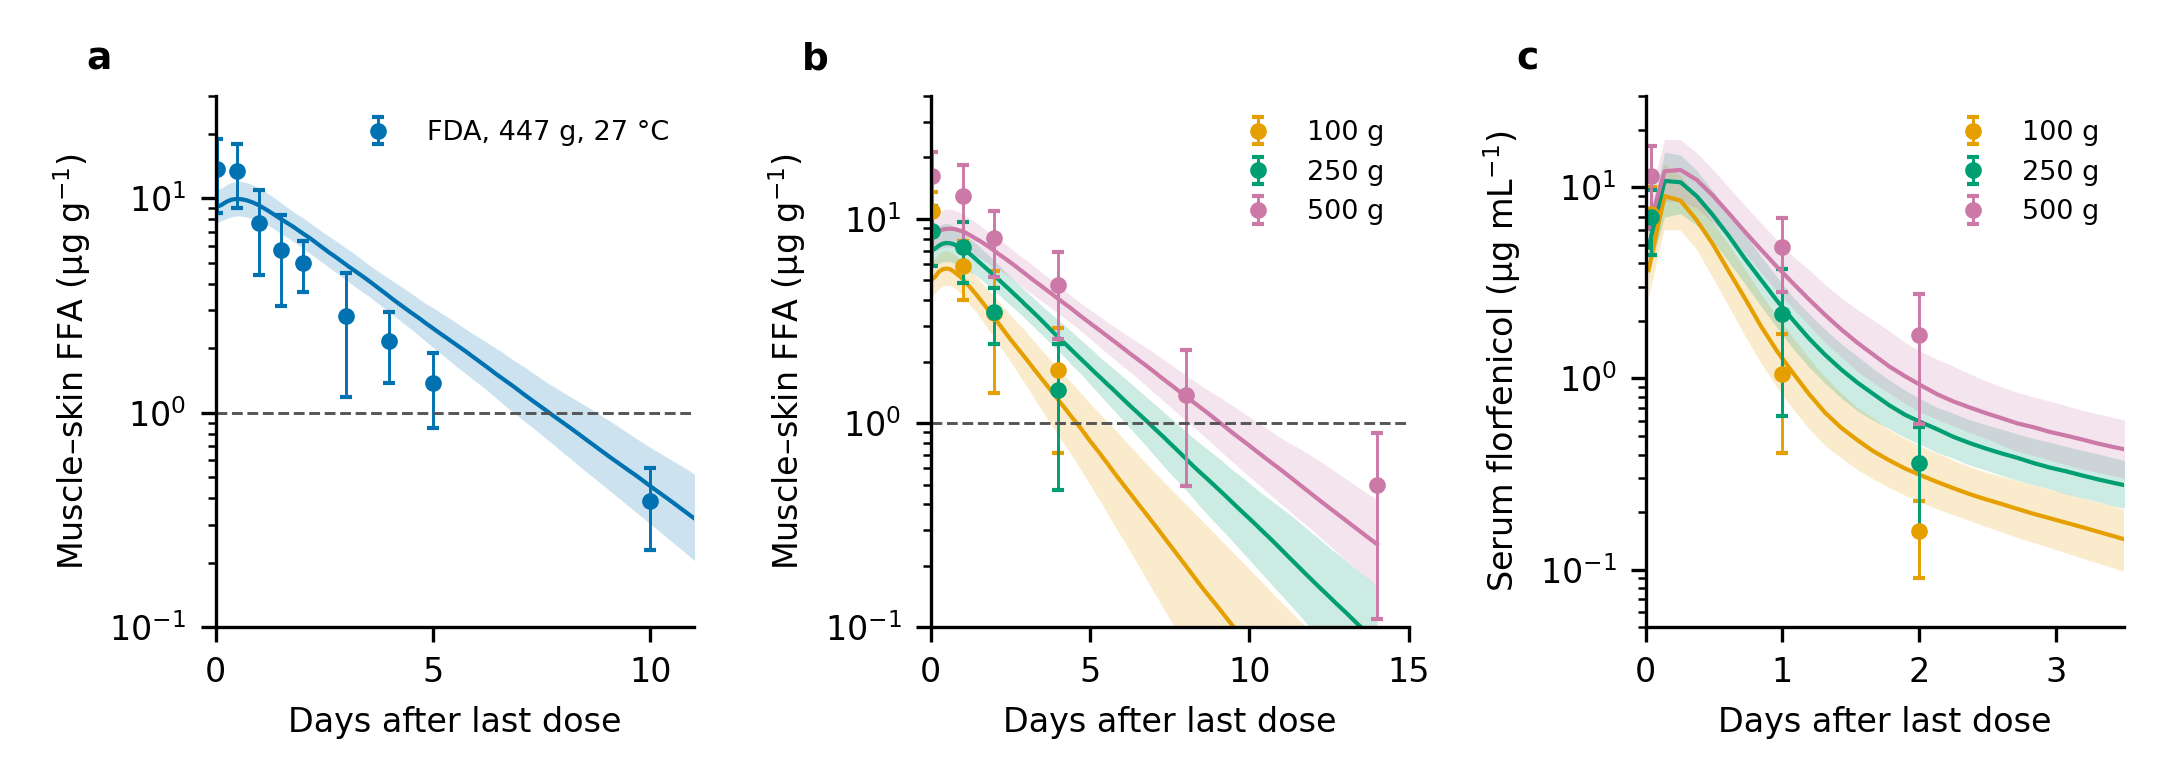

fig2_validation.png


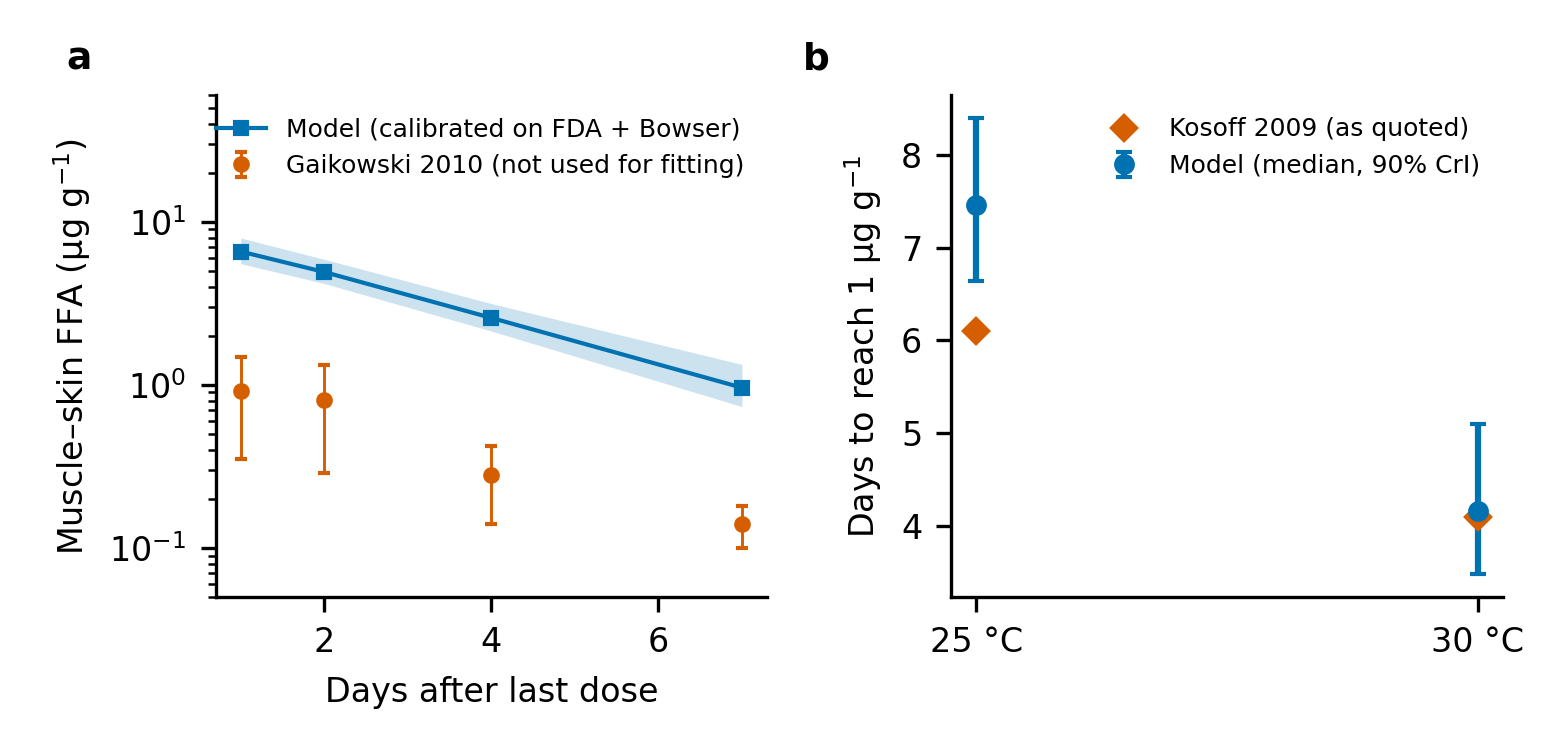

fig3_withdrawal_adi.png


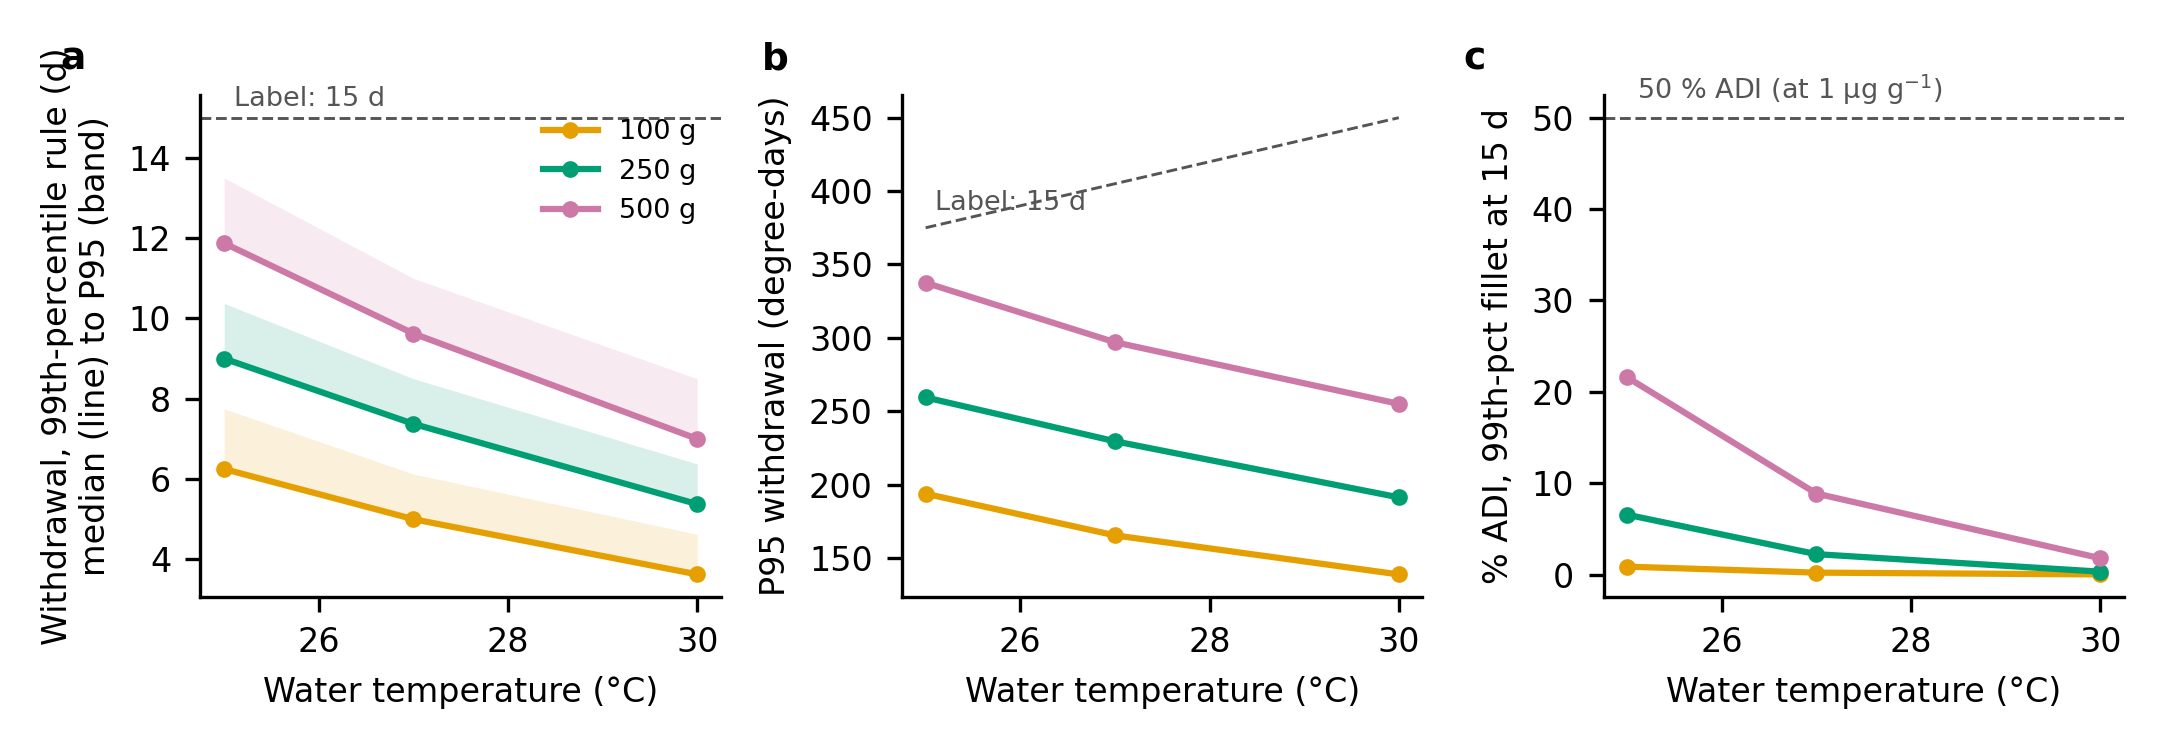

fig4_environment.png


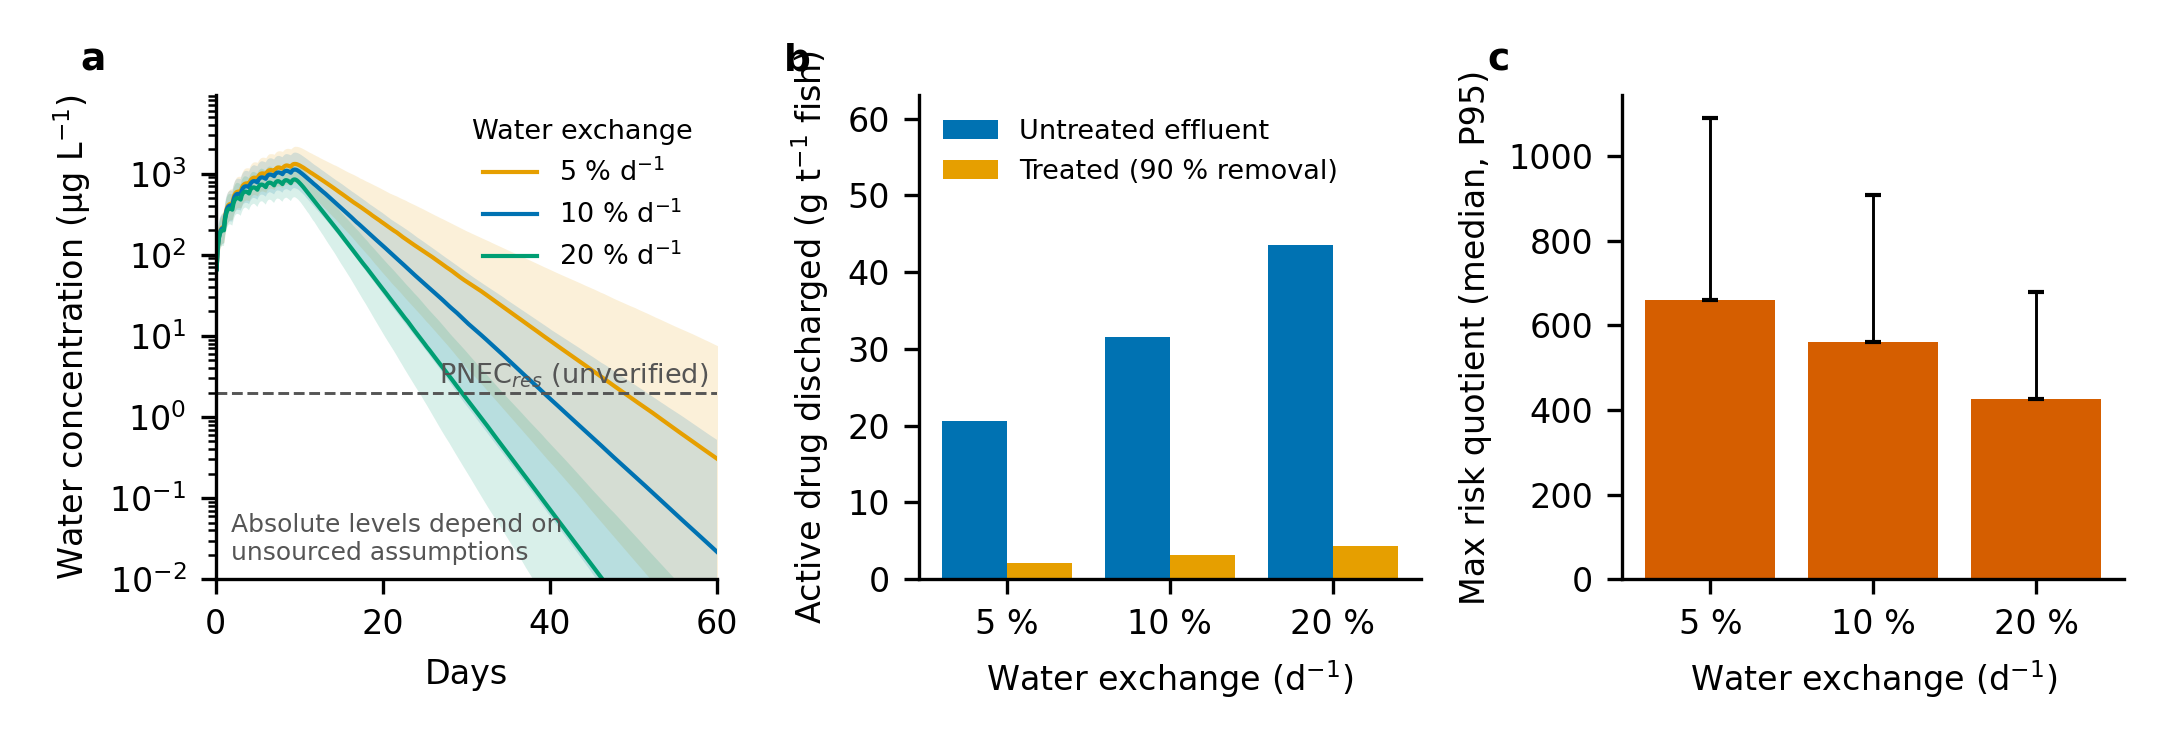

fig5_prcc.png


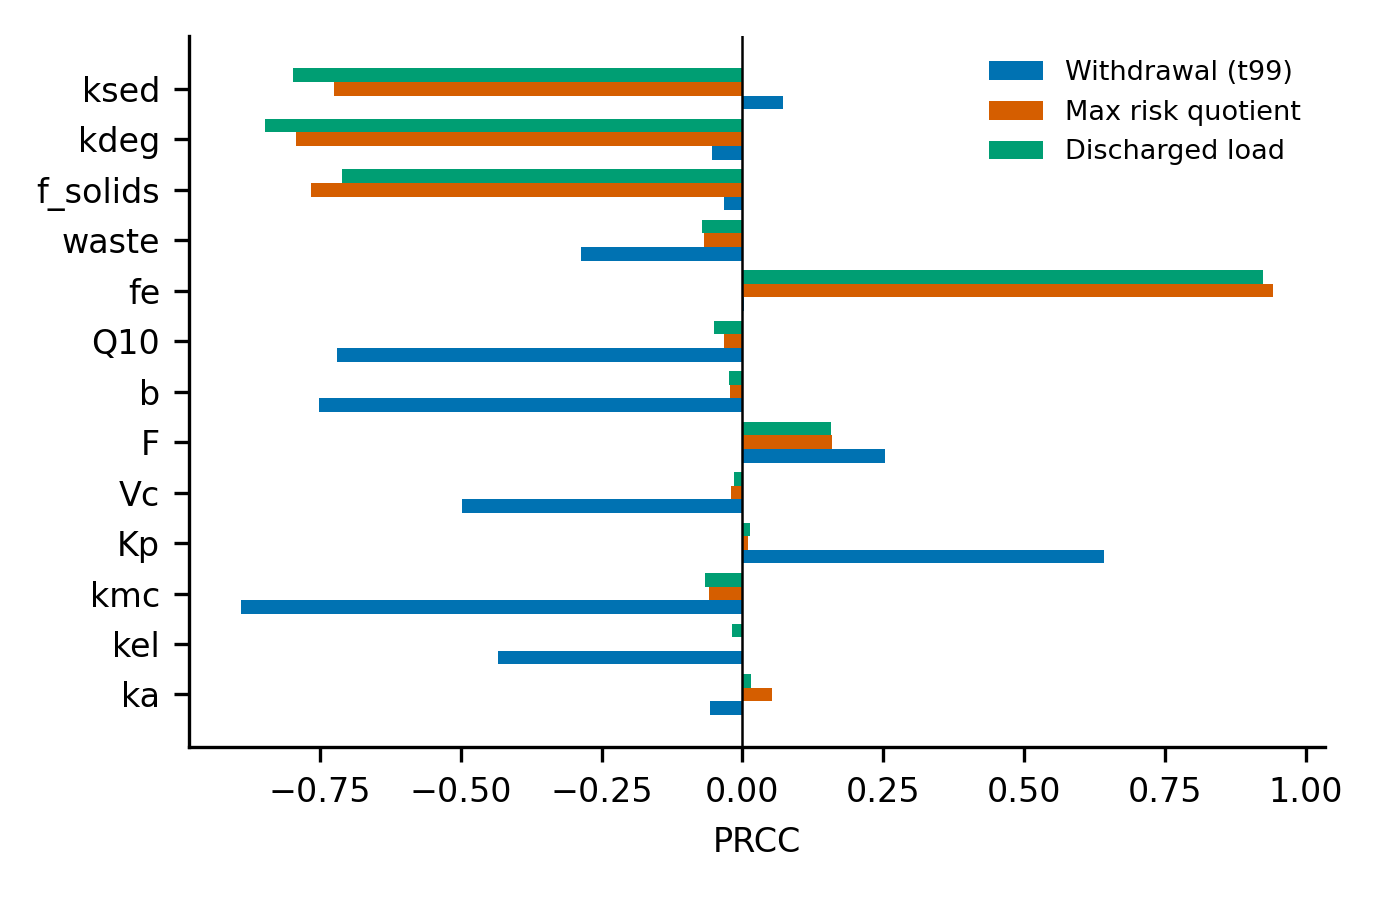

In [10]:
results = run_all("results_v3")

from IPython.display import Image, display
for f in sorted(os.listdir("results_v3")):
    if f.endswith(".png"):
        print(f); display(Image(f"results_v3/{f}"))